In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy.stats import shapiro, ttest_ind, mannwhitneyu, chi2_contingency, spearmanr, kruskal
from sklearn.preprocessing import PowerTransformer

import warnings
warnings.filterwarnings("ignore")

In [433]:
df = pd.read_excel('Online_Store.xlsx', sheet_name='Dim_Fact')

# EDA (Exploratory Data Analysis)

In [434]:
df.head()

,Fact_ID,Customer_ID,Product_ID,Shipping_ID,OrderPriority_ID,Market_ID,Date_ID,Geography_ID,Sales,Quantity,Discount,Profit,Shipping_Cost,Is_Returned
0,1,SC-20575,OFF-LA-10002782,4,1,7,23644,293,13.080000,3,0.0,4.560000,1.033,0
1,2,KW-16570,FUR-FU-10004015,4,1,7,19143,1522,252.160004,8,0.0,90.720001,13.449,0
2,3,KW-16570,FUR-BO-10002352,4,1,7,19143,1522,193.279999,2,0.0,54.080002,9.627,0
3,4,KW-16570,OFF-BI-10004428,4,1,7,19143,1522,35.439999,4,0.0,4.960000,1.371,0
4,5,KW-16570,OFF-AR-10004594,4,1,7,19143,1522,71.599998,2,0.0,11.440000,3.787,0


In [435]:
print(df.shape)

(50849, 14)


In [436]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50849 entries, 0 to 50848
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Fact_ID           50849 non-null  int64  
 1   Customer_ID       50849 non-null  object 
 2   Product_ID        50849 non-null  object 
 3   Shipping_ID       50849 non-null  int64  
 4   OrderPriority_ID  50849 non-null  int64  
 5   Market_ID         50849 non-null  int64  
 6   Date_ID           50849 non-null  int64  
 7   Geography_ID      50849 non-null  int64  
 8   Sales             50849 non-null  float64
 9   Quantity          50849 non-null  int64  
 10  Discount          50849 non-null  float64
 11  Profit            50849 non-null  float64
 12  Shipping_Cost     50849 non-null  float64
 13  Is_Returned       50849 non-null  int64  
dtypes: float64(4), int64(8), object(2)
memory usage: 5.4+ MB


In [437]:
df.isna().sum()

Fact_ID             0
Customer_ID         0
Product_ID          0
Shipping_ID         0
OrderPriority_ID    0
Market_ID           0
Date_ID             0
Geography_ID        0
Sales               0
Quantity            0
Discount            0
Profit              0
Shipping_Cost       0
Is_Returned         0
dtype: int64

In [438]:
df.duplicated().sum()

np.int64(0)

There are no missing values and no duplicated records.

In [439]:
df[['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping_Cost']].describe()

,Sales,Quantity,Discount,Profit,Shipping_Cost
count,50849.000000,50849.000000,50849.000000,50849.000000,50849.000000
mean,243.844229,3.464001,0.141077,29.065890,26.041735
std,483.847523,2.273332,0.211647,171.462556,56.758415
min,0.444000,1.000000,0.000000,-6599.979980,0.002000
25%,30.510000,2.000000,0.000000,0.000000,2.570000
50%,84.300003,3.000000,0.000000,9.300000,7.700000
75%,248.580002,5.000000,0.200000,36.810001,24.068001
max,22638.500000,14.000000,0.850000,8399.980469,933.570007


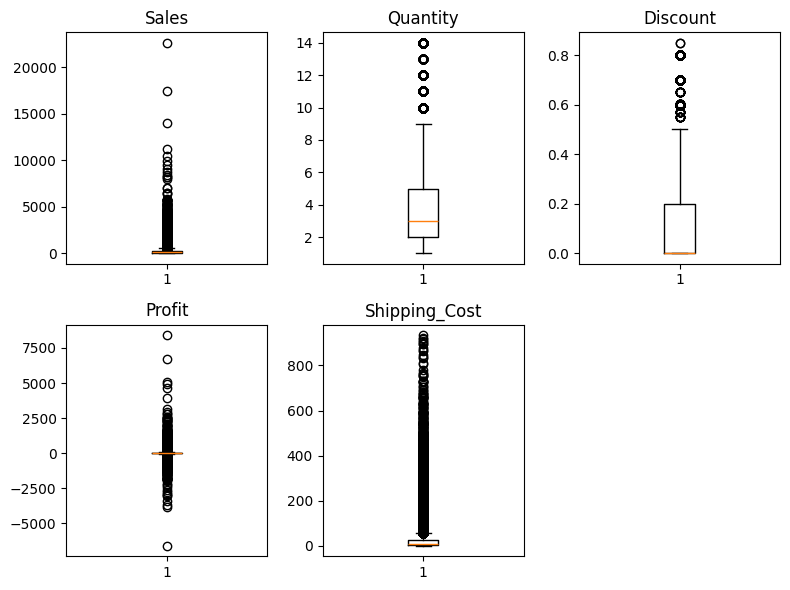

In [440]:
fig, axes = plt.subplots(2, 3 , figsize=(8, 6))

axes[0, 0].boxplot(df['Sales'])
axes[0, 0].set_title('Sales')

axes[0, 1].boxplot(df['Quantity'])
axes[0, 1].set_title('Quantity')

axes[0, 2].boxplot(df['Discount'])
axes[0, 2].set_title('Discount')

axes[1, 0].boxplot(df['Profit'])
axes[1, 0].set_title('Profit')

axes[1, 1].boxplot(df['Shipping_Cost'])
axes[1, 1].set_title('Shipping_Cost')

fig.delaxes(axes[1,2])

plt.tight_layout()


Here we can see that most variables, like Sales and Shipping Cost, contain outliers,
which makes them highly skewed to the right. Most values are small, but there are 
some large values that appear as outliers.
It is important to notice the negative outliers in Profit, which means some orders have caused losses.
Quantity looks more balanced, and we do not see many unusual values.
The Discount values are mostly zero, which means most sold items did not have a discount.

Outliers were not removed because these numbers can be normal in this context.

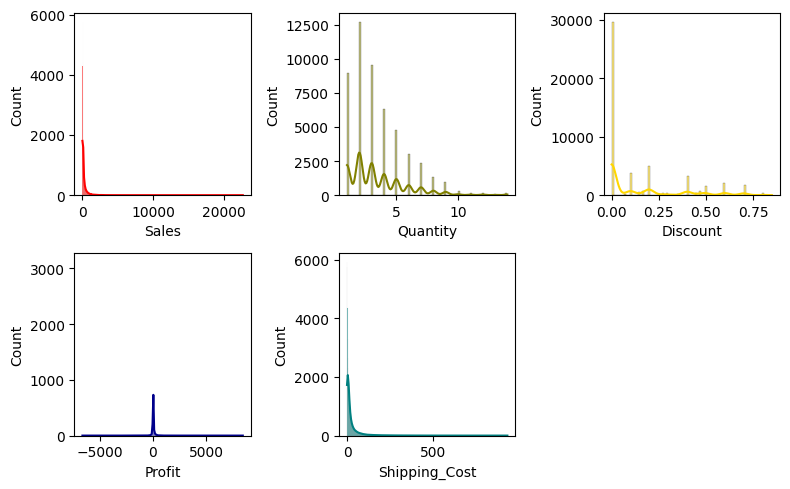

In [441]:
fig, axes = plt.subplots(2, 3, figsize= (8,5))

sns.histplot(data=df, x='Sales', kde=True, color='red',ax=axes[0,0])
sns.histplot(data=df, x='Quantity', kde=True, color='olive',ax=axes[0,1])
sns.histplot(data=df, x='Discount', kde=True, color='gold',ax=axes[0,2])
sns.histplot(data=df, x='Profit', kde=True, color='darkblue',ax=axes[1,0])
sns.histplot(data=df, x='Shipping_Cost', kde=True, color='teal',ax=axes[1,1])

fig.delaxes(axes[1,2])

plt.tight_layout()
plt.show()

The histograms show most variables are right skewed and not normally distributed.
In fact, in sales data, it is common for the data to be skewed, and it is rare for it to be normally distributed.

## Splitting The Data into Two Groups:


In [442]:
with_discount = df[df['Discount'] > 0]    
without_discount = df[df['Discount'] == 0] 

In [443]:
with_discount['Sales'].describe()

count    21687.000000
mean       248.789559
std        482.625231
min          0.444000
25%         26.024000
50%         82.559998
75%        265.824005
max      22638.500000
Name: Sales, dtype: float64

In [444]:
without_discount['Sales'].describe()

count    29162.000000
mean       240.166520
std        484.730068
min          0.990000
25%         33.480000
50%         85.320000
75%        237.817497
max      17499.900391
Name: Sales, dtype: float64

In [445]:
print(len(with_discount), len(without_discount))

21687 29162


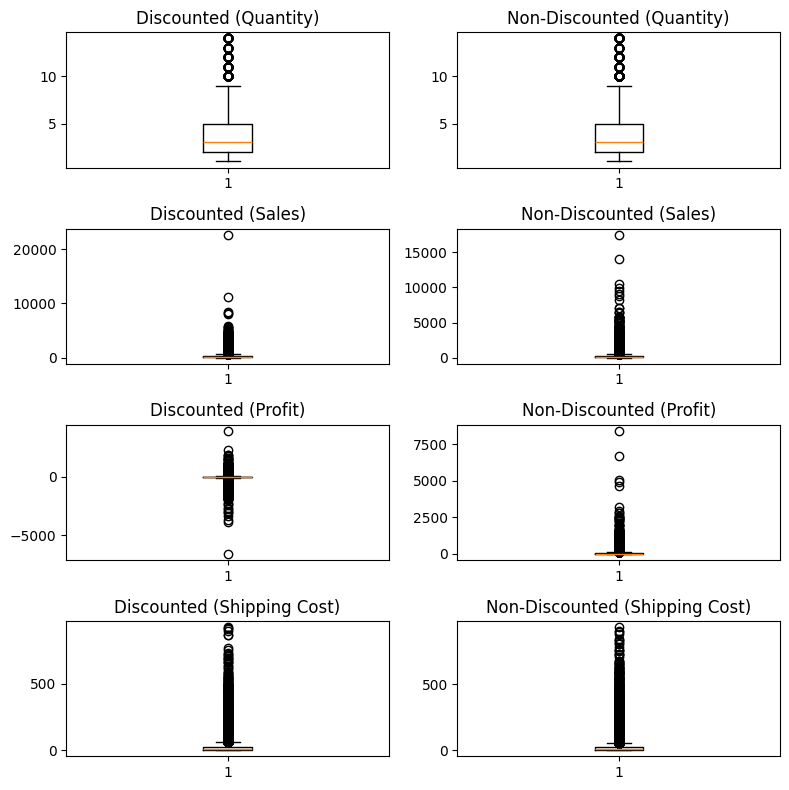

In [446]:
fig, axes = plt.subplots(4, 2 , figsize=(8,8))

axes[0, 0].boxplot(with_discount["Quantity"])
axes[0, 0].set_title('Discounted (Quantity)')

axes[0, 1].boxplot(without_discount["Quantity"])
axes[0, 1].set_title('Non-Discounted (Quantity)')

#-----------------------------------------------------

axes[1, 0].boxplot(with_discount["Sales"])
axes[1, 0].set_title('Discounted (Sales)')

axes[1, 1].boxplot(without_discount["Sales"])
axes[1, 1].set_title('Non-Discounted (Sales)')

#-----------------------------------------------------

axes[2, 0].boxplot(with_discount["Profit"])
axes[2, 0].set_title('Discounted (Profit)')

axes[2, 1].boxplot(without_discount["Profit"])
axes[2, 1].set_title('Non-Discounted (Profit)')

#-----------------------------------------------------
axes[3, 0].boxplot(with_discount["Shipping_Cost"])
axes[3, 0].set_title('Discounted (Shipping Cost)')

axes[3, 1].boxplot(without_discount["Shipping_Cost"])
axes[3, 1].set_title('Non-Discounted (Shipping Cost)')

plt.tight_layout()
plt.show()

The data does't show a significant difference in quantity between orders with discount and orders without discount. Although a statistical test is needed to cofirm this.

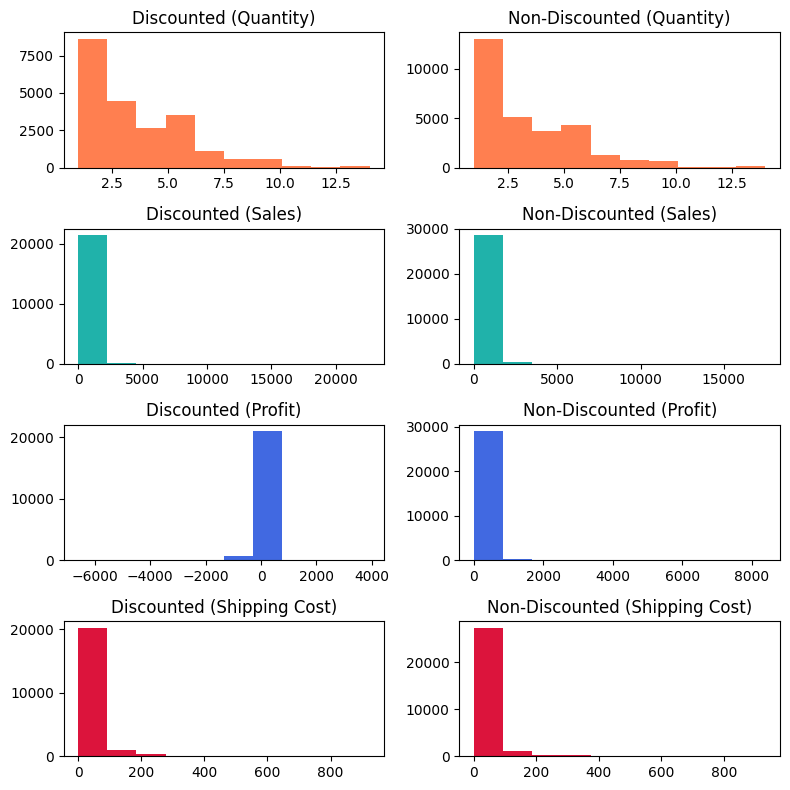

In [447]:
fig, axes = plt.subplots(4, 2 , figsize=(8,8))

axes[0, 0].hist(with_discount["Quantity"], color='coral')
axes[0, 0].set_title('Discounted (Quantity)')

axes[0, 1].hist(without_discount["Quantity"], color='coral')
axes[0, 1].set_title('Non-Discounted (Quantity)')

#-----------------------------------------------------

axes[1, 0].hist(with_discount["Sales"], color='lightseagreen')
axes[1, 0].set_title('Discounted (Sales)')

axes[1, 1].hist(without_discount["Sales"], color='lightseagreen')
axes[1, 1].set_title('Non-Discounted (Sales)')

#-----------------------------------------------------

axes[2, 0].hist(with_discount["Profit"], color='royalblue')
axes[2, 0].set_title('Discounted (Profit)')

axes[2, 1].hist(without_discount["Profit"], color='royalblue')
axes[2, 1].set_title('Non-Discounted (Profit)')

#-----------------------------------------------------
axes[3, 0].hist(with_discount["Shipping_Cost"], color='crimson')
axes[3, 0].set_title('Discounted (Shipping Cost)')

axes[3, 1].hist(without_discount["Shipping_Cost"], color='crimson')
axes[3, 1].set_title('Non-Discounted (Shipping Cost)')

plt.tight_layout()
plt.show()

In [448]:
print(f'Mean of Discounted Quantities: {with_discount["Quantity"].mean()}')
print(f'Mean of Non-discounted Quantities: {without_discount["Quantity"].mean()}')
print(f'Median of Discounted Quantities: {with_discount["Quantity"].median()}')
print(f'Median of Non-discounted Quantities: {without_discount["Quantity"].median()}')

Mean of Discounted Quantities: 3.561626781020888
Mean of Non-discounted Quantities: 3.391399766819834
Median of Discounted Quantities: 3.0
Median of Non-discounted Quantities: 3.0


This comparison shows that the average quantity for discounted items is only slightly higher than for non-discounted ones, and both groups share the same median. Overall, these results suggest that discounts do not have a noticeable impact on the number of items sold.

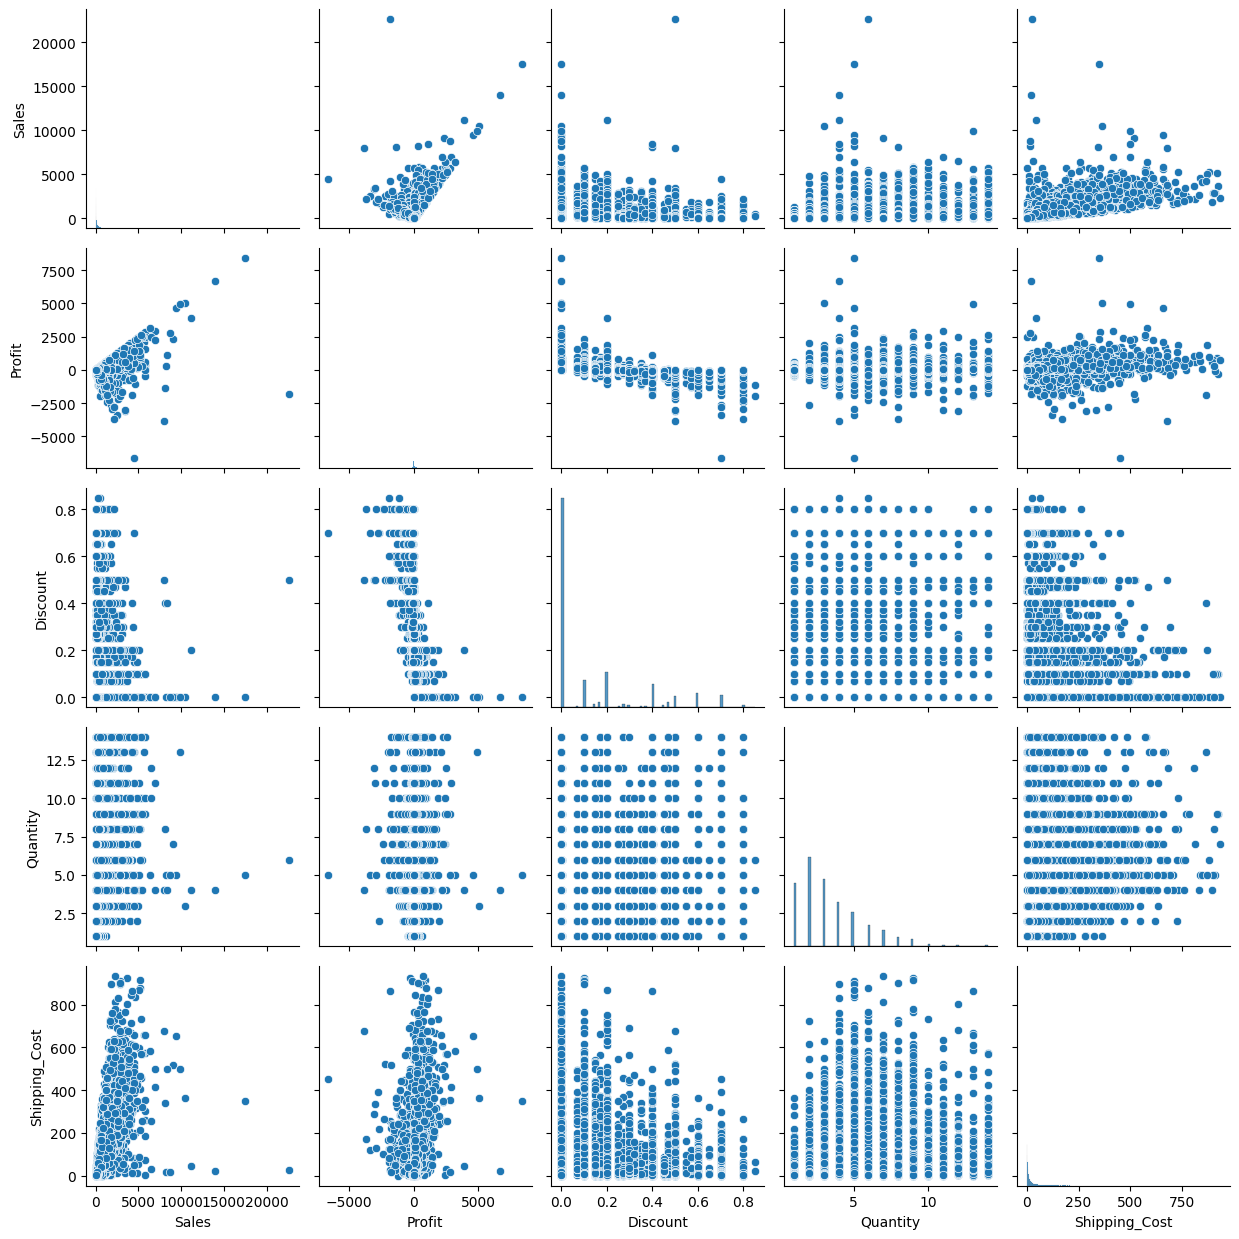

In [ ]:
features = ['Sales', 'Profit', 'Discount', 'Quantity', 'Shipping_Cost']
sns.pairplot(df[features])

plt.tight_layout()
plt.show()


## Sales vs Profit:  
The pairplots show a positive relationship between Sales and Profit. In general, higher sales usually lead to higher profit, but there are still some orders with high sales and low profit.  
## Discount vs Profit:  
There is a negative relationship between Discount and Profit. Higher discounts can reduce profit and sometimes even lead to losses.  
## Discount vs Sales:  
Discount doesn't have a strong impact on Sales. Some discounted items have high sales but not always.  
## Discount vs Quantity:  
There is no clear link between Discount and Quantity.  


In [450]:
correlation_matrix = df[features].corr()

print(correlation_matrix)


                  Sales    Profit  Discount  Quantity  Shipping_Cost
Sales          1.000000  0.491657 -0.086668  0.313899       0.768898
Profit         0.491657  1.000000 -0.316452  0.107797       0.357906
Discount      -0.086668 -0.316452  1.000000 -0.018321      -0.078975
Quantity       0.313899  0.107797 -0.018321  1.000000       0.273425
Shipping_Cost  0.768898  0.357906 -0.078975  0.273425       1.000000


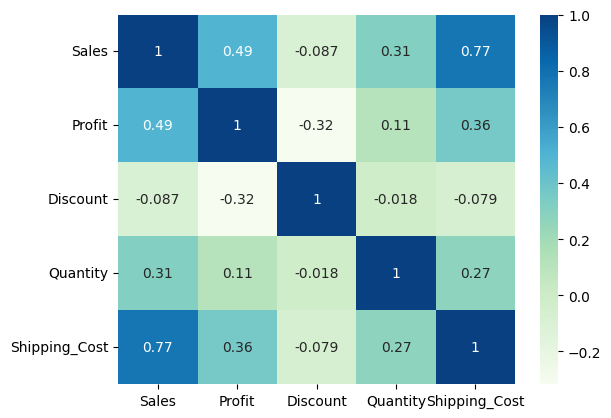

In [451]:
sns.heatmap(correlation_matrix, cmap='GnBu', annot=True)

plt.show()

In [452]:
df2 = pd.read_excel('Online_Store.xlsx', sheet_name='Dim_Shipping')

merged_df = df.merge(df2, how='left', on='Shipping_ID')

In [453]:
shipping_mode_counts = merged_df['Shipping_Mode'].value_counts()
shipping_mode_counts

Shipping_Mode
Standard Class    30617
Second Class      10158
First Class        7385
Same Day           2689
Name: count, dtype: int64

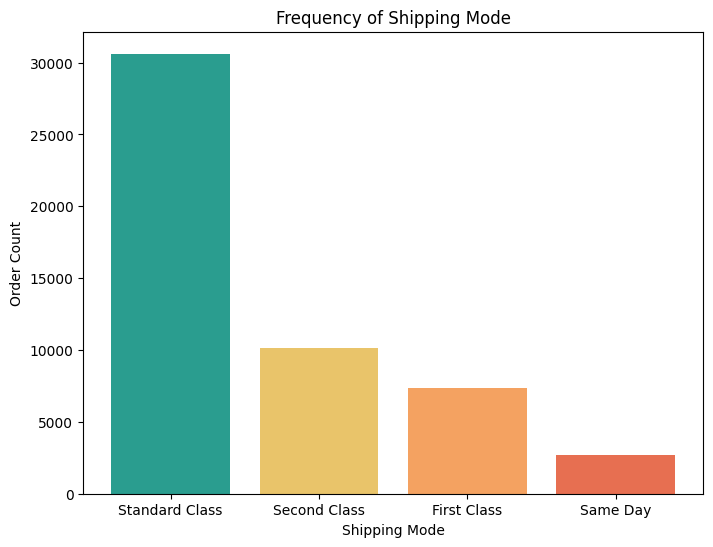

In [454]:
shipping_mode_counts = merged_df['Shipping_Mode'].value_counts()

plt.subplots(figsize=(8, 6))

plt.bar(
    shipping_mode_counts.index,
    shipping_mode_counts.values,
    color=['#2a9d8f', '#e9c46a', '#f4a261', '#e76f51']
)

plt.xlabel('Shipping Mode')
plt.ylabel('Order Count')
plt.title('Frequency of Shipping Mode')
plt.show()

It seems that customers prefer Standard Class delivery due to its lower cost rather than Same Day delivery, which has a higher cost.

In [455]:
df3 = pd.read_excel('Online_Store.xlsx', sheet_name='Dim_Product')

In [456]:
category_counts = df3['Category'].value_counts()
category_counts

Category
Office Supplies    5674
Technology         2365
Furniture          2207
Name: count, dtype: int64

In [457]:
sub_category_counts = df3['Sub-Category'].value_counts()
sub_category_counts

Sub-Category
Paper          779
Binders        740
Phones         691
Furnishings    681
Art            673
Accessories    663
Storage        648
Chairs         610
Envelopes      584
Labels         584
Fasteners      570
Bookcases      556
Appliances     548
Supplies       548
Copiers        515
Machines       496
Tables         360
Name: count, dtype: int64

In [458]:
#https://plotly.com/python/sunburst-charts/
#https://plotly.com/python/discrete-color/

fig = px.sunburst(
    df3,
    path=['Category', 'Sub-Category'],
    color='Category',
    color_discrete_sequence=px.colors.qualitative.Pastel
)

fig.update_layout(
    title = 'Product Distribution Overview',
    width=1000,
    height=600,
)

fig.show()


It appears that Office Supplies has the highest number of sold items.

In [459]:
df4 = pd.read_excel('Online_Store.xlsx', sheet_name='Dim_Geography')
merge_geo = df.merge(df4, how='left', on='Geography_ID')

In [460]:
country_profit_sum =merge_geo.groupby('Country')['Profit'].sum().reset_index()

fig = px.choropleth(
    country_profit_sum,
    locations='Country',
    locationmode='country names',
    color='Profit',
    color_continuous_scale='Blues',
    title= 'Total Profit Per Country'
                        )

fig.update_layout(
    width=1000,
    height=800
)

fig.show()

In this section, we first calculated the total profit for each Customer_ID, and then identified the top 10 customers with the highest profit and the top 10 customers with the greatest loss.

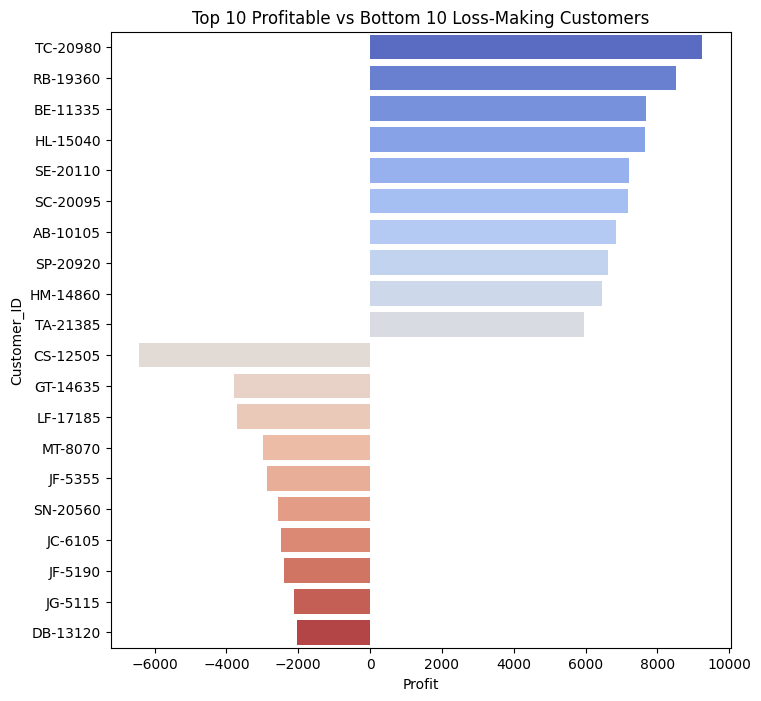

In [461]:
customer_profit = df.groupby('Customer_ID')['Profit'].sum().reset_index()

top_10_profit = customer_profit.nlargest(10, 'Profit')
bottom_10_profit = customer_profit.nsmallest(10, 'Profit')

combined_data = pd.concat([top_10_profit, bottom_10_profit])

plt.figure(figsize=(8, 8))
sns.barplot(x='Profit', y='Customer_ID', data=combined_data, palette='coolwarm')
plt.title('Top 10 Profitable vs Bottom 10 Loss-Making Customers')

plt.show()

Using the same approach as before, we identified the 10 products that generated the highest profit for the business and the 10 products that resulted in the lowest profit.

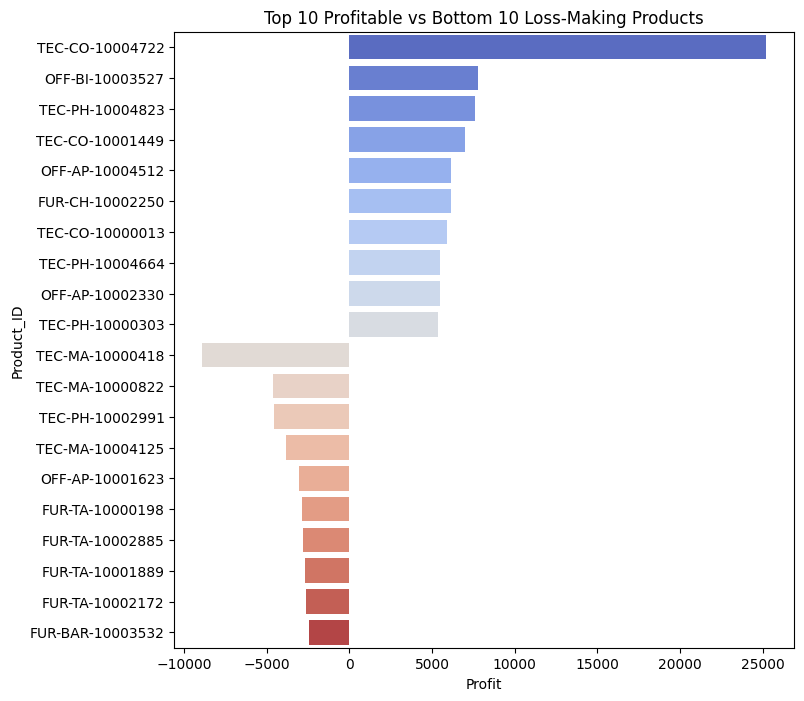

In [462]:
product_profit = df.groupby('Product_ID')['Profit'].sum().reset_index()

top_10_profit = product_profit.nlargest(10, 'Profit')
bottom_10_profit = product_profit.nsmallest(10, 'Profit')

combined_data = pd.concat([top_10_profit, bottom_10_profit])


plt.figure(figsize=(8, 8))
sns.barplot(x='Profit', y='Product_ID', data=combined_data, palette='coolwarm')
plt.title('Top 10 Profitable vs Bottom 10 Loss-Making Products')

plt.show()

In the next step, we also examined the 10 most profitable countries and the 10 countries that generated the highest losses:

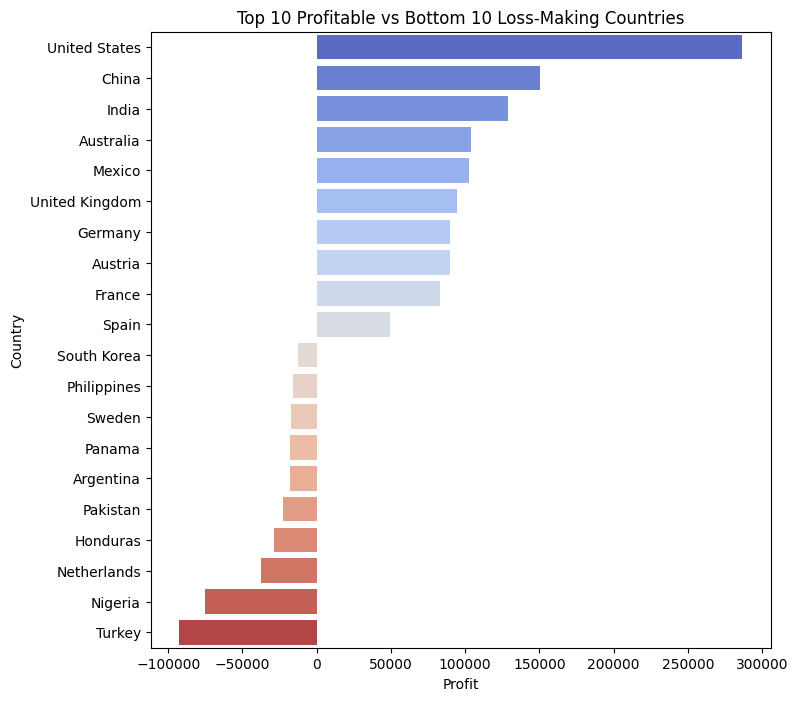

In [463]:
country_profit = merge_geo.groupby('Country')['Profit'].sum().reset_index()

top_10 = country_profit.nlargest(10, 'Profit')
bottom_10 = country_profit.nsmallest(10, 'Profit')

combined = pd.concat([top_10, bottom_10]).sort_values('Profit', ascending=False)

plt.figure(figsize=(8,8))
sns.barplot(x='Profit', y='Country', data=combined, errorbar=None, palette='coolwarm')
plt.title('Top 10 Profitable vs Bottom 10 Loss-Making Countries')
plt.show()

# Shapiro Wilk Test (Normality Test)

In [464]:
def check_normality(data, alpha=0.05):
    stat, p_value = shapiro(data)

    print('Shapiro-Test:')
    print(f'Statistics: {stat:.4f}, p_value: {p_value:.4f}')

    if p_value > alpha:
        print('The data is normally distributed.')
    else:
        print('The data is not normally distributed.')


In [465]:
check_normality(without_discount['Quantity'])
check_normality(with_discount['Quantity'])
print('--------------------------------------')
check_normality(without_discount['Profit'])
check_normality(with_discount['Profit'])
print('--------------------------------------')
check_normality(without_discount['Sales'])
check_normality(with_discount['Sales'])
print('--------------------------------------')
check_normality(without_discount['Shipping_Cost'])
check_normality(with_discount['Shipping_Cost'])

Shapiro-Test:
Statistics: 0.8618, p_value: 0.0000
The data is not normally distributed.
Shapiro-Test:
Statistics: 0.8729, p_value: 0.0000
The data is not normally distributed.
--------------------------------------
Shapiro-Test:
Statistics: 0.3264, p_value: 0.0000
The data is not normally distributed.
Shapiro-Test:
Statistics: 0.5045, p_value: 0.0000
The data is not normally distributed.
--------------------------------------
Shapiro-Test:
Statistics: 0.4512, p_value: 0.0000
The data is not normally distributed.
Shapiro-Test:
Statistics: 0.4823, p_value: 0.0000
The data is not normally distributed.
--------------------------------------
Shapiro-Test:
Statistics: 0.4278, p_value: 0.0000
The data is not normally distributed.
Shapiro-Test:
Statistics: 0.4575, p_value: 0.0000
The data is not normally distributed.


The Shapiro test shows that the data is not normally distributed (p-value < 0.05). Therefore, the Mann–Whitney U test, a non-parametric test, was used instead of a parametric test such as the independent t-test.

Checking the possibility of normalization using the Yeo-johnson method:

In [466]:
X1 = with_discount['Quantity']
X1_reshaped = X1.values.reshape(-1, 1)
transformer = PowerTransformer(method='yeo-johnson')
X1_transformed = transformer.fit_transform(X1_reshaped)

discounted_yeojohnson= pd.Series(X1_transformed.flatten())


X2 = without_discount['Quantity']
X2_reshaped = X2.values.reshape(-1, 1)
transformer = PowerTransformer(method='yeo-johnson')
X2_transformed = transformer.fit_transform(X2_reshaped)

without_discount_yeojohnson= pd.Series(X2_transformed.flatten())

After applying the normalization method, we checked the normality of the discount and non‑discount groups again using the Shapiro test, and the results showed that the data still did not become normally distributed:

In [467]:
check_normality(discounted_yeojohnson)
print('----------------------------------')
check_normality(without_discount_yeojohnson)

Shapiro-Test:
Statistics: 0.9472, p_value: 0.0000
The data is not normally distributed.
----------------------------------
Shapiro-Test:
Statistics: 0.9348, p_value: 0.0000
The data is not normally distributed.


## Hypothesis:
Null Hypothesis: Discount doesn't have any significant effect on the variables.  
Alternative Hypothesis: Discount has a significant effect on the variables.

So, to answer the question, we use the Mann–Whitney test. Here, the null hypothesis says that offering discounts does not have a meaningful effect on our sales. Then we check to see whether we can reject this idea or not:

# Man-Whitney U test

In [468]:
def mann_whitney_test (x, y, alpha=0.05):
    stat,p_value = mannwhitneyu(x, y)

    print(f'statistics: {stat}')
    print(f'P_value: {p_value}')

    if p_value < alpha:
        print('Reject Null Hypothesis')
    else:
        print('Do not Reject Null Hypothesis')

In [469]:
mann_whitney_test(with_discount['Quantity'], without_discount['Quantity'])
print('-----------------------------------------------------------------')
mann_whitney_test(with_discount['Sales'], without_discount['Sales'])
print('-----------------------------------------------------------------')
mann_whitney_test(with_discount['Profit'], without_discount['Profit'])
print('-----------------------------------------------------------------')
mann_whitney_test(with_discount['Shipping_Cost'], without_discount['Shipping_Cost'])

statistics: 334440997.0
P_value: 1.208876672202363e-29
Reject Null Hypothesis
-----------------------------------------------------------------
statistics: 307660645.5
P_value: 1.7193288200101263e-07
Reject Null Hypothesis
-----------------------------------------------------------------
statistics: 136650326.5
P_value: 0.0
Reject Null Hypothesis
-----------------------------------------------------------------
statistics: 308193651.0
P_value: 9.496822922000762e-07
Reject Null Hypothesis


Mann-Whitney test shows that discounts have a significant effect on Quantity, Sale, Profit and Shipping Cost. Since P_value < 0.05 , we reject null hypothesis.

In this section, we examine how the season affects the number of products sold and whether there is a meaningful relationship between the month of sale and the increase or decrease in purchase levels:

In [470]:
seasons = {
    1: 'Winter', 2: 'Winter', 3: 'Spring',
    4: 'Spring', 5: 'Spring', 6: 'Summer',
    7: 'Summer', 8: 'Summer', 9: 'Autumn',
    10: 'Autumn', 11: 'Autumn', 12: 'Winter'
}

df_date = pd.read_excel("Online_Store.xlsx",sheet_name="Dim_Date")
df_fact = pd.read_excel("Online_Store.xlsx", sheet_name='Dim_Fact')
df_merged = pd.merge(df_date, df_fact[['Date_ID', 'Quantity']], on='Date_ID', how='left')
df_merged['season'] = df_merged['Order_Date_M'].map(seasons)
#df_merged

In [471]:
winter= df_merged[df_merged['season'] == 'Winter']['Quantity']
spring = df_merged[df_merged['season'] == 'Spring']['Quantity']
summer = df_merged[df_merged['season'] == 'Summer']['Quantity']
autumn = df_merged[df_merged['season'] == 'Autumn']['Quantity']

print("Winter")
check_normality(winter)
print('---------------------------------------')

print("Spring")
check_normality(spring)
print('---------------------------------------')

print("Summer")
check_normality(summer)
print('---------------------------------------')

print("Autumn")
check_normality(autumn)

Winter
Shapiro-Test:
Statistics: 0.8642, p_value: 0.0000
The data is not normally distributed.
---------------------------------------
Spring
Shapiro-Test:
Statistics: 0.8681, p_value: 0.0000
The data is not normally distributed.
---------------------------------------
Summer
Shapiro-Test:
Statistics: 0.8634, p_value: 0.0000
The data is not normally distributed.
---------------------------------------
Autumn
Shapiro-Test:
Statistics: 0.8718, p_value: 0.0000
The data is not normally distributed.


We ran the Shapiro test on all four groups, and none of them were normally distributed. Therefore, to test our null hypothesis, we used the Kruskal–Wallis statistical test.

# Kruskal–Wallis statistical test

In [472]:
from scipy.stats import kruskal

def kruskal_wallis_test(x, y, z, t, alpha=0.05):
    stat, p_value = kruskal(x, y, z, t)

    print(f'Statistics: {stat}')
    print(f'P_value: {p_value}')

    if p_value < alpha:
        print('Reject Null Hypothesis')
    else:
        print('Do not Reject Null Hypothesis')


In [473]:
kruskal_wallis_test(spring, summer, autumn, winter)

Statistics: 14.61660733716091
P_value: 0.0021754025073811266
Reject Null Hypothesis


Since the p‑value is below 0.05, we reject the null hypothesis. This means there is a statistically significant difference between the groups, indicating that the season of sale has a meaningful impact on product sales.

# Spearman's Rank Correlation test

In [474]:
def spearman_test(x, y , alpha=0.05):
    stat, p_value = spearmanr(x, y)

    print(f'Spearman Correlation: {stat}')
    print(f'p_value: {p_value}')

    if p_value < alpha:
        print('Reject Null Hypothesis')
    else:
        print('Do not Reject Null Hypothesis')

In [475]:
spearman_test(df['Discount'], df['Quantity'])

Spearman Correlation: 0.01919645184711845
p_value: 1.4976132292221942e-05
Reject Null Hypothesis


# Chi-squared test

In [476]:
def chi_squared_test(x, y, alpha=0.05):
    stat, p_value, dof, expected = chi2_contingency(x, y)

    print(f'Chi-squared Statistics: {stat}')
    print(f'P_value: {p_value}')

    if p_value < alpha:
        print('Reject Null Hypothesis')
    else:
        print('Do not Reject Null Hypothesis')

